<a href="https://colab.research.google.com/github/fauziihadiwijaya/Uts-deep-learning-2026/blob/main/Clustering/combination/Multimodal_Clustering_Material_Types.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 3 — Multimodal Clustering: Material Types (gabungan image + spectrum)**

## Summary

1. Tools: PyTorch dan scikit-learn
2. Input: image embedding (SimCLR, 256 dimensi) dan spectrum embedding (1D-CNN autoencoder, 32 dimensi)
3. Fusion: PCA 16 komponen per modalitas, varians disetarakan, lalu digabung
4. Jumlah cluster: silhouette, Calinski-Harabasz, Davies-Bouldin, BIC (GMM), stabilitas antar seed
5. Clustering: KMeans, GMM, DEC
6. Analisis: kNN purity per modalitas, UMAP atau t-SNE, pasangan cluster yang sulit dipisahkan
7. Output: cluster.csv (id_sampel, cluster)

Notebook ini adalah bagian yang dikerjakan bersama. Inputnya artefak dari dua notebook cabang: Image Representation & Encoder dan Spectrum Representation & Encoder. Eksplorasi distorsi citra ada di notebook image lalu eksplorasi distorsi spektrum ada di Bagian 3 notebook ini.

**Cara menjalankan (Colab):** taruh clustering.npz, clustering_meta.csv, image_encoder_artifacts.zip, dan spectrum_encoder_artifacts.zip di DATA_DIR, lalu Runtime → Run all. GPU membantu untuk DEC tetapi tidak wajib.

## **0. Setup Lingkungan & Hyperparameter**

Bagian ini menyiapkan pustaka, jalur input/output, random seed, dan hyperparameter fusion serta clustering dalam dictionary CFG. SMOKE menjalankan seluruh notebook dengan sedikit sampel untuk memastikan kode tidak error.

In [1]:
import os, sys, time, math, random, platform, warnings, json, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy
from scipy.stats import chi2_contingency
from scipy.ndimage import median_filter
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_DIR = Path(os.environ.get('DATA_DIR', '/content/drive/MyDrive/UTS_DL'))           # folder clustering.npz & clustering_meta.csv
SMOKE    = os.environ.get('SMOKE', '0') == '1'                                         # ubah ke True biar aktif

if str(DATA_DIR).startswith('/content/drive') and not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')

OUT_DIR = Path(os.environ.get('OUT_DIR', DATA_DIR / 'hasil_tugas3')) / ('smoke' if SMOKE else '')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,                                         # sama dengan kedua notebook encoder
    fuse_dim=16, w_img=1.0, w_spec=1.0,              # dimensi PCA per modalitas & bobot fusion
    mic_correct='auto',                              # koreksi efek mikroskop: 'auto', True, atau False
    k_range=list(range(2, 21)),                      # kandidat jumlah cluster
    dec_latent=10, dec_ae_epochs=50, dec_epochs=100, dec_tol=0.001,   # DEC
    seeds=[0, 1, 2],                                 # seed untuk uji stabilitas clustering
    n_sil=5000, n_gmm=10000, n_vis=6000,             # ukuran subsampel untuk metrik yang mahal
)
if SMOKE:
    CFG.update(k_range=[2, 3, 4, 5], dec_ae_epochs=2, dec_epochs=3, n_vis=300)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = dev.type == 'cuda'                              # mixed precision di GPU
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']   # urutan warna tetap
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'lines.linewidth': 1.8, 'axes.prop_cycle': mpl.cycler(color=PAL),
                     'axes.titlesize': 10, 'axes.labelsize': 9, 'legend.frameon': False, 'legend.fontsize': 8})

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

print('python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__, '| umap', umap.__version__ if HAS_UMAP else 'tidak ada (pakai t-SNE)')
print('device:', torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'CPU', '| out:', OUT_DIR)

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | umap 0.5.12
device: Tesla T4 | out: /content/drive/MyDrive/UTS_DL/hasil_tugas3


## 1. Load data

Citra dan spektrum mentah dimuat bukan untuk training, melainkan untuk memeriksa distorsi spektrum dan untuk menafsirkan isi setiap cluster (galeri citra dan kurva spektrum per cluster). Pemeriksaan assert memastikan urutan metadata sama dengan urutan array.

In [2]:
meta = pd.read_csv(DATA_DIR / 'clustering_meta.csv')
z = np.load(DATA_DIR / 'clustering.npz')
img_all, spec_raw = z['gambar'], z['spektrum'].astype(np.float32)
assert img_all.shape[1:] == (64, 64) and spec_raw.shape[1] == 128
assert len(meta) == len(img_all) == len(spec_raw)
assert (meta['indeks'].values == np.arange(len(meta))).all() and meta['id_sampel'].is_unique

if SMOKE:   # ambil sebagian kecil sampel (seed sama di kedua notebook agar id_sampel cocok)
    keep = np.sort(np.random.default_rng(0).choice(len(meta), min(400, len(meta)), replace=False))
    meta, img_all, spec_raw = meta.iloc[keep].reset_index(drop=True), img_all[keep], spec_raw[keep]

N = len(meta)
MICS = ['M1', 'M2']
mic = (meta['mikroskop'] == 'M2').values.astype(np.int64)      # 0 = M1, 1 = M2
print('gambar', img_all.shape, '| spektrum', spec_raw.shape, '| sampel', N)

gambar (36000, 64, 64) | spektrum (36000, 128) | sampel 36000


## 2. Memuat image & spectrum embedding

Notebook mencari artefak kedua cabang di beberapa lokasi (DATA_DIR, DATA_DIR/hasil_tugas3, dan OUT_DIR). Jika yang tersedia hanya file zip, file tersebut diekstrak otomatis. Kedua embedding digabung ke metadata berdasarkan **id_sampel**, bukan urutan baris, dengan validate='one_to_one'. Lalu dicek bahwa tidak ada sampel yang kehilangan embedding dan kolom mikroskop dari ketiga file sama.

In [3]:
def find_artifact(folder, csv_names):
    """Cari file embedding di folder artefak; ekstrak zip-nya jika hanya zip yang ada."""
    roots = [OUT_DIR, DATA_DIR, DATA_DIR / 'hasil_tugas3']
    for r in roots:
        for name in csv_names:
            for p in [r / folder / name, r / name]:
                if p.exists(): return p
    for r in roots:
        zp = r / f'{folder}.zip'
        if zp.exists():
            dst = OUT_DIR / folder; dst.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zp) as zf: zf.extractall(dst)
            for name in csv_names:
                if (dst / name).exists(): return dst / name
    raise FileNotFoundError(f'{csv_names[0]} tidak ditemukan. Jalankan notebook {folder.split("_")[0]} encoder, '
                            f'lalu taruh folder atau {folder}.zip di {DATA_DIR}.')

def load_embedding(path, prefix):
    df = pd.read_csv(path)
    cols = [c for c in df.columns if c.startswith(prefix)]
    assert df['id_sampel'].is_unique and len(cols) > 0, f'format {path.name} tidak sesuai'
    keep_cols = ['id_sampel'] + (['mikroskop'] if 'mikroskop' in df else []) + cols
    m = meta[['id_sampel', 'mikroskop']].merge(df[keep_cols], on='id_sampel', how='left',
                                              validate='one_to_one', suffixes=('', '_emb'))
    assert m[cols].notna().all().all(), f'ada id_sampel yang tidak punya embedding di {path.name}'
    if 'mikroskop_emb' in m:
        assert (m['mikroskop'] == m['mikroskop_emb']).all(), f'kolom mikroskop di {path.name} tidak sama'
    return m[cols].values.astype(np.float32)

img_path = find_artifact('image_encoder_artifacts', ['image_embeddings.csv.gz', 'image_embeddings.csv'])
spec_path = find_artifact('spectrum_encoder_artifacts', ['spectrum_embeddings.csv'])
E_img, E_spec = load_embedding(img_path, 'image_emb_'), load_embedding(spec_path, 'spectrum_emb_')
print('image embedding   ', E_img.shape, 'dari', img_path)
print('spectrum embedding', E_spec.shape, 'dari', spec_path)

image embedding    (36000, 256) dari /content/drive/MyDrive/UTS_DL/hasil_tugas3/image_encoder_artifacts/image_embeddings.csv.gz
spectrum embedding (36000, 32) dari /content/drive/MyDrive/UTS_DL/hasil_tugas3/spectrum_encoder_artifacts/spectrum_embeddings.csv


## 3. Exploration (a): distorsi spektrum

Distorsi citra (rotasi, skala, brightness, perbedaan mikroskop) sudah diperiksa di notebook image. Bagian ini memeriksa tiga distorsi spektrum yang disebut di soal:
- **Shift**: posisi puncak tertinggi (argmax). Material yang sama tetapi spektrumnya bergeser akan punya posisi puncak yang tersebar.
- **Baseline**: offset (rata-rata 8 titik paling kiri) dan kemiringan (selisih ujung kanan dan kiri). Baseline yang bervariasi menggeser seluruh kurva tanpa mengubah komposisi.
- **Spike**: titik yang menyimpang dari median filter lokal lebih dari 6 kali simpangan robust dan lebih dari 10% rentang spektrum. Spike adalah lonjakan sempit satu atau dua titik, berbeda dengan puncak komposisi yang lebih lebar.

Jika distorsi ini besar, spectrum encoder (autoencoder tanpa augmentasi) ikut mempelajarinya, sehingga cluster bisa terbentuk berdasarkan baseline atau spike, bukan komposisi.

posisi_puncak         baseline_offset        baseline_slope         \
                   mean     std            mean    std           mean    std   
mikroskop                                                                      
M1               51.062  28.300            0.31  0.181         -0.000  0.399   
M2               50.805  28.164            0.31  0.181         -0.005  0.400   

          jumlah_spike        ada_spike         
                  mean    std      mean    std  
mikroskop                                       
M1               0.995  1.263     0.588  0.492  
M2               1.007  1.291     0.590  0.492

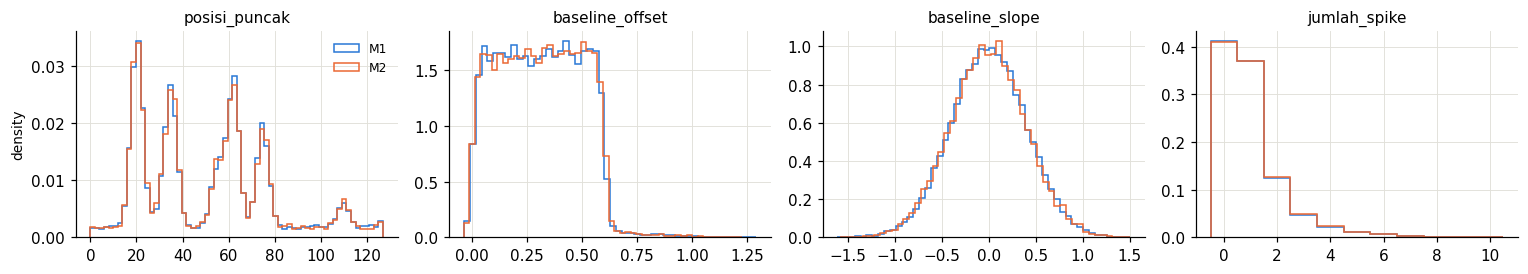

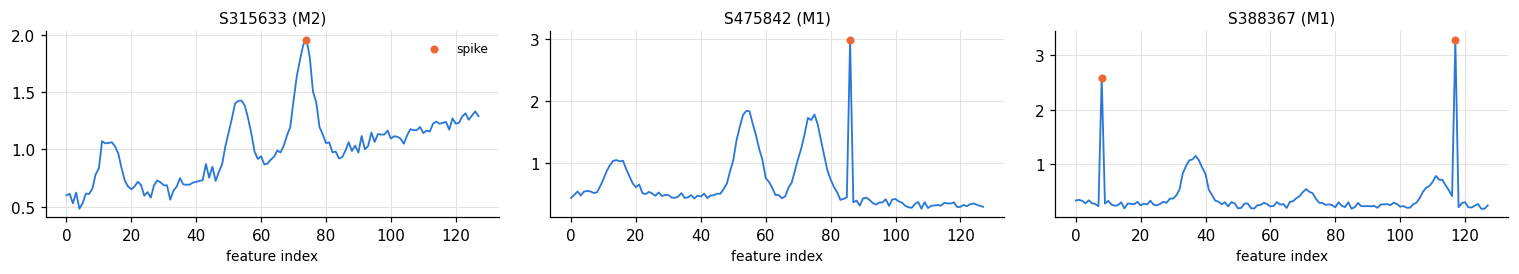

In [4]:
peak_pos = spec_raw.argmax(1)
base_off = spec_raw[:, :8].mean(1)
base_slope = spec_raw[:, -8:].mean(1) - spec_raw[:, :8].mean(1)
resid = spec_raw - median_filter(spec_raw, size=(1, 5), mode='nearest')
mad = 1.4826 * np.median(np.abs(resid - np.median(resid, 1, keepdims=True)), 1, keepdims=True) + 1e-6
rng_spec = (spec_raw.max(1) - spec_raw.min(1))[:, None]
spike_mask = (np.abs(resid) > 6 * mad) & (np.abs(resid) > 0.1 * rng_spec)   # cukup tajam DAN cukup tinggi
n_spike = spike_mask.sum(1)

sst = pd.DataFrame({'posisi_puncak': peak_pos, 'baseline_offset': base_off, 'baseline_slope': base_slope,
                    'jumlah_spike': n_spike, 'ada_spike': n_spike > 0, 'mikroskop': meta['mikroskop'].values})
display(sst.groupby('mikroskop').agg(['mean', 'std']).round(3))

fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, col, bins in zip(axes, ['posisi_puncak', 'baseline_offset', 'baseline_slope', 'jumlah_spike'], [64, 50, 50, np.arange(0, 12) - 0.5]):
    for m, name in enumerate(MICS):
        ax.hist(sst[col][mic == m], bins=bins, histtype='step', density=True, color=PAL[m], lw=1.6, label=name)
    ax.set_title(col)
axes[0].set_ylabel('density'); axes[0].legend()
plt.tight_layout(); plt.show()

ex = np.where(n_spike > 0)[0][:3] if (n_spike > 0).any() else np.arange(3)
fig, axes = plt.subplots(1, 3, figsize=(14, 2.6))
for ax, i in zip(axes, ex):
    ax.plot(spec_raw[i], color=PAL[0], lw=1.2)
    ax.scatter(np.where(spike_mask[i])[0], spec_raw[i][spike_mask[i]], color=PAL[1], s=18, zorder=3, label='spike')
    ax.set_title(f"{meta['id_sampel'][i]} ({meta['mikroskop'][i]})"); ax.set_xlabel('feature index')
axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Fusion (c)

**Koreksi efek mikroskop.** Sebelum digabung, setiap embedding diuji apakah bisa menebak mikroskop (balanced accuracy regresi logistik, 5-fold; 0.5 berarti tidak ada informasi mikroskop). Spektrum dipakai sebagai pembanding karena spektrum mengukur komposisi dan tidak dihasilkan oleh mikroskop. Jika spektrum tidak bisa menebak mikroskop, berarti proporsi material di M1 dan M2 sama, sehingga informasi mikroskop yang terbawa di image embedding adalah efek alat (batch effect), bukan perbedaan material. Pada kondisi itu image embedding distandardisasi per mikroskop: setiap dimensi dikurangi rata-rata dan dibagi simpangan baku mikroskopnya sendiri. Aturan ini berjalan otomatis (mic_correct='auto') dan bisa dipaksa aktif atau mati lewat CFG.

**Penggabungan.** Image embedding berdimensi 256, spectrum embedding 32. Kalau langsung digabung, gambar akan mendominasi jarak hanya karena jumlah dimensinya lebih banyak. Karena itu setiap modalitas diproses terpisah:
1. Standardisasi per dimensi.
2. PCA menjadi 16 komponen, untuk membuang dimensi yang redundan dan menyamakan jumlah dimensi.
3. Skala ulang agar total varians tiap modalitas sama dengan 1, sehingga kedua modalitas punya pengaruh setara terhadap jarak.
4. Digabung (concat) dengan bobot w_img dan w_spec (default 1:1).

Hasilnya tiga ruang yang dibandingkan pada bagian berikutnya: image saja, spectrum saja, dan fused.

In [5]:
def leakage(E, n=10000):
    """Balanced accuracy menebak mikroskop dari embedding (0.5 = tidak ada informasi mikroskop)."""
    sub = np.random.default_rng(1).choice(N, min(n, N), replace=False)
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    pred = cross_val_predict(LogisticRegression(max_iter=3000), StandardScaler().fit_transform(E[sub]), mic[sub], cv=cv)
    return balanced_accuracy_score(mic[sub], pred)

def per_mic_standardize(E):
    """Standardisasi setiap dimensi di dalam masing-masing mikroskop."""
    E = E.copy()
    for k in (0, 1):
        m = mic == k
        E[m] = (E[m] - E[m].mean(0)) / (E[m].std(0) + 1e-6)
    return E

leak = {'image': leakage(E_img), 'spectrum': leakage(E_spec)}
if CFG['mic_correct'] == 'auto':
    correct = {'image': leak['image'] > 0.6 and leak['spectrum'] < 0.6,
               'spectrum': leak['spectrum'] > 0.6 and leak['image'] < 0.6}
else:
    correct = {'image': bool(CFG['mic_correct']), 'spectrum': False}
E_img_f = per_mic_standardize(E_img) if correct['image'] else E_img
E_spec_f = per_mic_standardize(E_spec) if correct['spectrum'] else E_spec
tab_leak = pd.DataFrame({'bocor_mikroskop_awal': leak, 'dikoreksi': correct,
                         'bocor_mikroskop_akhir': {'image': leakage(E_img_f), 'spectrum': leakage(E_spec_f)}})
display(tab_leak.round(4))

def reduce_block(E, d, seed):
    Z = StandardScaler().fit_transform(E)
    pca = PCA(min(d, Z.shape[1], len(Z)), random_state=seed).fit(Z)
    P = pca.transform(Z)
    return (P / np.sqrt(P.var(0).sum())).astype(np.float32), pca.explained_variance_ratio_.sum()

R_img, ev_img = reduce_block(E_img_f, CFG['fuse_dim'], CFG['seed'])
R_spec, ev_spec = reduce_block(E_spec_f, CFG['fuse_dim'], CFG['seed'])
VIEWS = {'image': R_img, 'spectrum': R_spec,
         'fused': np.concatenate([CFG['w_img'] * R_img, CFG['w_spec'] * R_spec], 1)}
X = VIEWS['fused']
print(f'PCA {CFG["fuse_dim"]} komponen | varians terjelaskan image {ev_img:.1%} | spectrum {ev_spec:.1%} | fused {X.shape}')

,bocor_mikroskop_awal,dikoreksi,bocor_mikroskop_akhir
image,0.8670,True,0.4980
spectrum,0.4991,False,0.4991


PCA 16 komponen | varians terjelaskan image 88.1% | spectrum 86.7% | fused (36000, 32)


**Hasil koreksi dan fusion.** Image embedding bisa menebak mikroskop dengan balanced accuracy 0.867, sedangkan spectrum embedding hanya 0.499. Karena spektrum tidak berkaitan dengan mikroskop, proporsi material di M1 dan M2 bisa dianggap sama, sehingga informasi mikroskop di image embedding adalah efek alat. Sumbernya terlihat di notebook image: citra M2 lebih tajam dan skala teksturnya sekitar 1.3 kali lebih kecil dibanding M1 (5.49 vs 7.02 piksel), yang menunjukkan perbesaran kedua mikroskop berbeda. Setelah standardisasi per mikroskop, kebocoran image turun ke 0.498. PCA 16 komponen mempertahankan 88.1% varians image dan 86.7% varians spectrum, sehingga ruang fused berdimensi 32.

## 5. Menentukan jumlah cluster (e)

KMeans dijalankan untuk setiap k pada rentang 2 sampai 20 di ruang fused, lalu dinilai dengan empat kriteria yang masing-masing memberi satu suara:
- **Silhouette** (makin tinggi makin baik): seberapa dekat sampel ke cluster-nya dibanding cluster terdekat lain.
- **Calinski-Harabasz** (makin tinggi makin baik): rasio sebaran antar cluster terhadap sebaran dalam cluster.
- **Davies-Bouldin** (makin rendah makin baik): rata-rata kemiripan setiap cluster dengan cluster yang paling mirip dengannya.
- **BIC dari Gaussian Mixture** (makin rendah makin baik): keseimbangan antara kecocokan model dan jumlah parameter.

Sebagai pendukung ditampilkan elbow (inertia) dan **stabilitas**, yaitu rata-rata ARI antara tiga KMeans dengan seed berbeda. Jumlah cluster yang benar biasanya stabil, karena cluster yang dipaksa terbelah akan terbelah di tempat berbeda setiap kali dijalankan. K_FINAL diambil dari suara terbanyak; jika seri, dipilih yang sesuai silhouette. Isi K_OVERRIDE untuk memilih secara manual.

selesai dalam 257s


,inertia,silhouette,calinski_harabasz,davies_bouldin,bic,stabilitas
k,,,,,,
2,61121.0000,0.1706,6407.413574,1.8667,-282135.2488,0.3329
3,52887.9141,0.2038,6504.162598,2.0806,-357969.1358,1.0000
4,46594.8008,0.2414,6542.178223,1.6781,-427937.4748,0.8250
5,41917.5781,0.2485,6458.079102,1.5771,-462048.4650,1.0000
6,39304.9727,0.2514,5988.227539,1.6047,-474428.3311,0.8518
7,37851.2969,0.2067,5412.087402,1.7923,-501526.0384,0.7424
8,36559.6797,0.1747,4984.337891,2.0381,-525813.3604,0.9977
9,35745.9375,0.1724,4562.849121,2.0116,-534924.5783,0.8900
10,35032.2305,0.1612,4219.879883,2.1429,-545895.8256,0.8838


,silhouette,calinski_harabasz,davies_bouldin,bic
k terbaik,6,4,5,15


K_FINAL = 6 | suara: {6: 1, 4: 1, 5: 1, 15: 1}


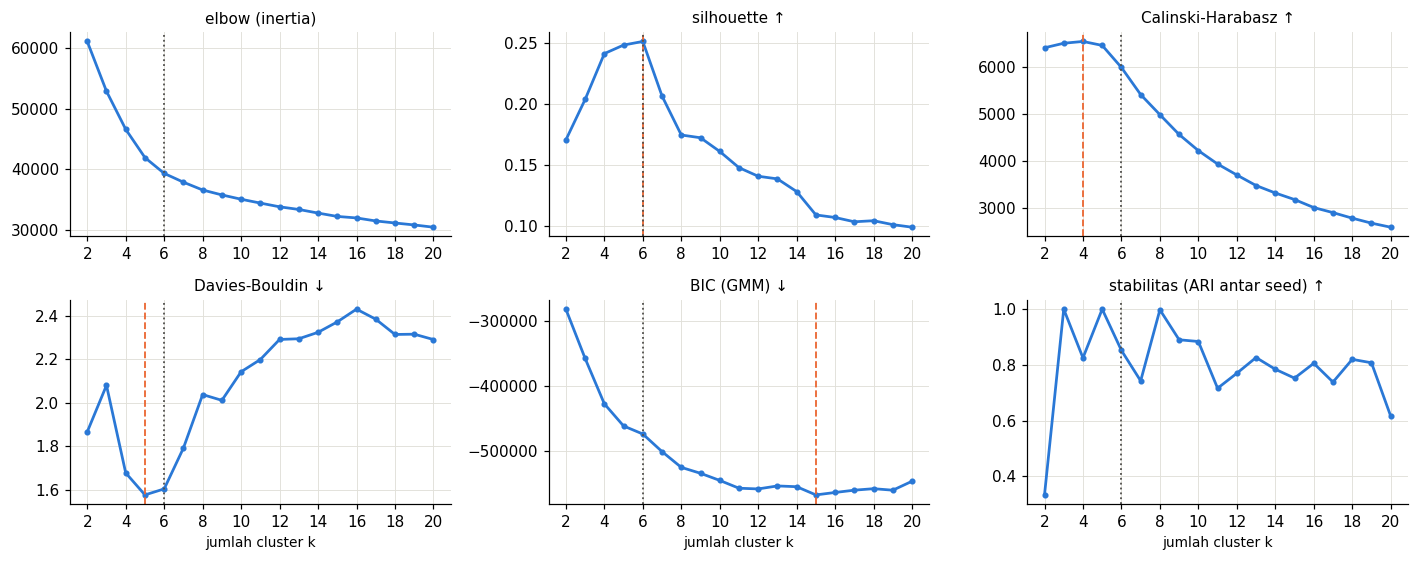

In [6]:
K_OVERRIDE = None
rs = np.random.default_rng(CFG['seed'])
sil_idx = rs.choice(N, min(CFG['n_sil'], N), replace=False)
gmm_idx = rs.choice(N, min(CFG['n_gmm'], N), replace=False)

def stability(Xv, k, seeds):
    labs = [KMeans(k, n_init=3, random_state=s).fit_predict(Xv) for s in seeds]
    return np.mean([adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))])

rows = []; t0 = time.time()
for k in CFG['k_range']:
    km = KMeans(k, n_init=10, random_state=CFG['seed']).fit(X)
    gmm = GaussianMixture(k, covariance_type='full', n_init=2, reg_covar=1e-4, random_state=CFG['seed']).fit(X[gmm_idx])
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X[sil_idx], km.labels_[sil_idx]),
                     calinski_harabasz=calinski_harabasz_score(X, km.labels_), davies_bouldin=davies_bouldin_score(X, km.labels_),
                     bic=gmm.bic(X[gmm_idx]), stabilitas=stability(X, k, [1, 2, 3])))
tab_k = pd.DataFrame(rows).set_index('k')
print(f'selesai dalam {time.time() - t0:.0f}s')
display(tab_k.round(4))

best = {'silhouette': tab_k['silhouette'].idxmax(), 'calinski_harabasz': tab_k['calinski_harabasz'].idxmax(),
        'davies_bouldin': tab_k['davies_bouldin'].idxmin(), 'bic': tab_k['bic'].idxmin()}
votes = pd.Series(best).value_counts()
top = votes[votes == votes.max()].index.tolist()
K_FINAL = int(K_OVERRIDE or (best['silhouette'] if best['silhouette'] in top else min(top)))
display(pd.Series(best, name='k terbaik').to_frame().T)
print('K_FINAL =', K_FINAL, '| suara:', votes.to_dict())

fig, axes = plt.subplots(2, 3, figsize=(13, 5.2))
panels = [('inertia', 'elbow (inertia)', None), ('silhouette', 'silhouette ↑', 'silhouette'),
          ('calinski_harabasz', 'Calinski-Harabasz ↑', 'calinski_harabasz'), ('davies_bouldin', 'Davies-Bouldin ↓', 'davies_bouldin'),
          ('bic', 'BIC (GMM) ↓', 'bic'), ('stabilitas', 'stabilitas (ARI antar seed) ↑', None)]
for ax, (col, title, crit) in zip(axes.ravel(), panels):
    ax.plot(tab_k.index, tab_k[col], color=PAL[0], marker='o', ms=3)
    if crit: ax.axvline(best[crit], color=PAL[1], ls='--', lw=1.2)
    ax.axvline(K_FINAL, color='#52514e', ls=':', lw=1.2)
    ax.set_title(title); ax.set_xticks(tab_k.index[::2] if len(tab_k) > 10 else tab_k.index)
for ax in axes[1]: ax.set_xlabel('jumlah cluster k')
plt.tight_layout(); plt.show()

**Hasil pemilihan jumlah cluster.** Keempat kriteria tidak sepakat: silhouette memilih k=6 (0.251), Calinski-Harabasz k=4, Davies-Bouldin k=5 (1.577, hanya sedikit lebih baik dari k=6 yang 1.605), dan BIC k=15. Karena setiap k mendapat satu suara, aturan seri memakai pilihan silhouette, sehingga K_FINAL = 6.

Alasan k=6 tetap dipakai meskipun suaranya terbagi:
1. Silhouette naik tajam sampai k=6 lalu turun drastis di k=7 (0.207) dan k=8 (0.175), artinya membelah lebih jauh memotong cluster yang sebenarnya utuh.
2. Davies-Bouldin juga berada di titik terendah pada k=5–6 dan naik setelahnya. Elbow inertia mulai melandai di sekitar k=6.
3. BIC terus turun sampai k=15 karena GMM kovarians penuh menutup setiap cluster yang bentuknya tidak Gaussian dengan beberapa komponen. BIC karena itu cenderung melebih-lebihkan jumlah cluster di data ini.
4. Visualisasi UMAP di Bagian 8 menunjukkan tepat enam pulau yang terpisah jelas.

Stabilitas KMeans (n_init=3) di k=6 adalah 0.85. Dengan n_init=20 seperti di Bagian 6, ketiga seed menghasilkan partisi yang sama (stabilitas 1.0).

## 6. Perbandingan metode clustering (d)

Tiga metode dijalankan pada ruang fused dengan K_FINAL cluster, masing-masing dengan tiga seed:
- **KMeans**: membagi ruang menjadi cluster bulat dengan ukuran sebaran mirip.
- **Gaussian Mixture (GMM)**: setiap cluster adalah distribusi Gaussian dengan kovarians penuh, sehingga bisa menangkap cluster lonjong dan ukuran berbeda.
- **DEC (Deep Embedded Clustering, Xie dkk., 2016)**: metode deep clustering. Autoencoder MLP (32 → 256 → 128 → 10) dilatih dulu untuk merekonstruksi embedding fused. Pusat cluster awal diambil dari KMeans di ruang laten 10 dimensi. Setelah itu encoder dan pusat cluster dilatih bersama dengan meminimalkan KL divergence antara soft assignment Q (distribusi Student-t) dan target P yang lebih tajam (Q kuadrat dinormalisasi). Training berhenti saat kurang dari 0.1% sampel berpindah cluster antar epoch.

Semua metode dinilai di ruang fused yang sama agar adil: silhouette, Calinski-Harabasz, Davies-Bouldin, stabilitas antar seed, dan Cramér's V terhadap mikroskop (0 berarti cluster tidak berkaitan dengan mikroskop, 1 berarti cluster sama persis dengan mikroskop). ARI terhadap label asli tidak bisa dihitung karena label disembunyikan, jadi pemilihan metode hanya bisa memakai kriteria internal ini.

KMeans selesai | 3s
GMM    selesai | 15s
DEC    selesai | 67s


,n_cluster,silhouette,calinski_harabasz,davies_bouldin,cramers_v_mikroskop,cluster_terkecil,cluster_terbesar,stabilitas
KMeans,6.0,0.2514,5988.2275,1.6047,0.0096,0.1016,0.279,1.0000
GMM,6.0,0.2514,5988.0708,1.6048,0.0096,0.1016,0.279,0.8586
DEC,6.0,0.2514,5985.4375,1.6056,0.0096,0.1016,0.279,0.9990


metode final (rata-rata peringkat silhouette, Davies-Bouldin, stabilitas): KMeans
kesepakatan antar metode (ARI):


,KMeans,GMM,DEC
KMeans,1.000,1.000,0.999
GMM,1.000,1.000,0.999
DEC,0.999,0.999,1.000


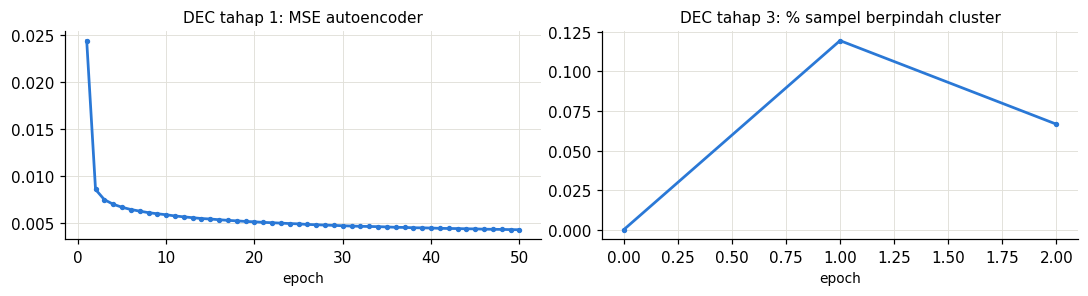

In [7]:
class DECNet(nn.Module):
    def __init__(self, d, lat):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, lat))
        self.dec = nn.Sequential(nn.Linear(lat, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, d))

def run_dec(Xv, k, seed, bs=256):
    path = OUT_DIR / f'dec_k{k}_s{seed}_d{Xv.shape[1]}_e{CFG["dec_ae_epochs"]}.pt'
    if path.exists():
        return torch.load(path, weights_only=False)
    set_seed(seed)
    Xt = torch.as_tensor(Xv, device=dev); n = len(Xt)
    net = DECNet(Xv.shape[1], CFG['dec_latent']).to(dev)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3); ae_hist = []
    for ep in range(CFG['dec_ae_epochs']):                                # tahap 1: pretrain autoencoder
        perm = torch.randperm(n, device=dev); L = 0.0
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            loss = F.mse_loss(net.dec(net.enc(Xt[b])), Xt[b])
            opt.zero_grad(); loss.backward(); opt.step(); L += loss.item() * len(b)
        ae_hist.append(L / n)
    with torch.no_grad():
        Z = net.enc(Xt).cpu().numpy()
    km = KMeans(k, n_init=20, random_state=seed).fit(Z)                  # tahap 2: inisialisasi pusat cluster
    mu = nn.Parameter(torch.tensor(km.cluster_centers_, dtype=torch.float32, device=dev))
    opt = torch.optim.Adam(list(net.enc.parameters()) + [mu], lr=1e-4)
    soft = lambda z: (lambda q: q / q.sum(1, keepdim=True))(1.0 / (1.0 + torch.cdist(z, mu) ** 2))   # Student-t, alpha=1
    prev, dec_hist = km.labels_, []
    for ep in range(CFG['dec_epochs']):                                   # tahap 3: KL(P || Q)
        with torch.no_grad():
            q = soft(net.enc(Xt)); p = q ** 2 / q.sum(0); p = p / p.sum(1, keepdim=True)
        lab = q.argmax(1).cpu().numpy(); delta = float((lab != prev).mean()); prev = lab
        if ep > 0 and delta < CFG['dec_tol']:
            dec_hist.append(dict(epoch=ep, kl=np.nan, delta=delta)); break
        perm = torch.randperm(n, device=dev); L = 0.0
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            loss = F.kl_div(soft(net.enc(Xt[b])).log(), p[b], reduction='batchmean')
            opt.zero_grad(); loss.backward(); opt.step(); L += loss.item() * len(b)
        dec_hist.append(dict(epoch=ep, kl=L / n, delta=delta))
    with torch.no_grad():
        labels = soft(net.enc(Xt)).argmax(1).cpu().numpy()
    R = dict(labels=labels, ae_hist=ae_hist, dec_hist=dec_hist, state={k_: v.cpu() for k_, v in net.state_dict().items()}, mu=mu.detach().cpu())
    torch.save(R, path)
    return R

METHODS = {
    'KMeans': lambda Xv, k, s: KMeans(k, n_init=20, random_state=s).fit_predict(Xv),
    'GMM':    lambda Xv, k, s: GaussianMixture(k, covariance_type='full', n_init=2, reg_covar=1e-4, random_state=s).fit(Xv).predict(Xv),
    'DEC':    lambda Xv, k, s: run_dec(Xv, k, s)['labels'],
}
LABELS = {}; t0 = time.time()
for m, f in METHODS.items():
    LABELS[m] = [f(X, K_FINAL, s) for s in CFG['seeds']]
    print(f'{m:6s} selesai | {time.time() - t0:.0f}s')

def cramers_v(a, b):
    ct = pd.crosstab(a, b).values
    if min(ct.shape) < 2: return 0.0
    return float(np.sqrt(chi2_contingency(ct)[0] / ct.sum() / (min(ct.shape) - 1)))

def internal_scores(lab, Xv=X):
    ok = len(np.unique(lab)) > 1
    share = np.bincount(lab, minlength=K_FINAL) / len(lab)
    return dict(n_cluster=int((share > 0).sum()),
                silhouette=silhouette_score(Xv[sil_idx], lab[sil_idx]) if ok else np.nan,
                calinski_harabasz=calinski_harabasz_score(Xv, lab) if ok else np.nan,
                davies_bouldin=davies_bouldin_score(Xv, lab) if ok else np.nan,
                cramers_v_mikroskop=cramers_v(lab, mic), cluster_terkecil=share[share > 0].min(), cluster_terbesar=share.max())

tab_m = pd.DataFrame({m: {**internal_scores(L[0]),
                          'stabilitas': np.mean([adjusted_rand_score(L[i], L[j]) for i in range(len(L)) for j in range(i + 1, len(L))])}
                      for m, L in LABELS.items()}).T
rank = tab_m['silhouette'].rank(ascending=False) + tab_m['davies_bouldin'].rank() + tab_m['stabilitas'].rank(ascending=False)
FINAL_METHOD = rank.idxmin()          # ubah manual jika ingin metode lain, misalnya 'DEC'
display(tab_m.round(4))
print('metode final (rata-rata peringkat silhouette, Davies-Bouldin, stabilitas):', FINAL_METHOD)

agree = pd.DataFrame([[adjusted_rand_score(LABELS[a][0], LABELS[b][0]) for b in LABELS] for a in LABELS], index=list(LABELS), columns=list(LABELS))
print('kesepakatan antar metode (ARI):'); display(agree.round(3))

dec0 = run_dec(X, K_FINAL, CFG['seeds'][0])
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].plot(np.arange(1, len(dec0['ae_hist']) + 1), dec0['ae_hist'], marker='o', ms=2.5); axes[0].set_title('DEC tahap 1: MSE autoencoder'); axes[0].set_xlabel('epoch')
dh = pd.DataFrame(dec0['dec_hist'])
axes[1].plot(dh['epoch'], dh['delta'] * 100, marker='o', ms=2.5); axes[1].set_title('DEC tahap 3: % sampel berpindah cluster'); axes[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

**Hasil perbandingan metode.** Ketiga metode menghasilkan partisi yang hampir sama: ARI antar metode 0.999–1.000, silhouette 0.2514, ukuran cluster terkecil 10.2% dan terbesar 27.9%. Cramér's V terhadap mikroskop hanya 0.0096, artinya cluster tidak mengikuti mikroskop, dan setiap cluster berisi sekitar 40% sampel M2, sama dengan proporsi keseluruhan.

- **KMeans** stabil sempurna di ketiga seed (1.000) dan terpilih sebagai metode final.
- **GMM** stabilitasnya 0.859, karena salah satu seed menemukan pembagian yang sedikit berbeda.
- **DEC** berhenti setelah dua epoch. Kurva tahap 3 menunjukkan hanya 0.12% lalu 0.07% sampel yang berpindah cluster, di bawah batas 0.1%. DEC hampir tidak mengubah inisialisasi KMeans karena cluster di ruang fused sudah terpisah jelas, sehingga tidak ada yang perlu dipertajam. Autoencoder DEC sendiri konvergen dengan MSE sekitar 0.004.

Kesepakatan setinggi ini menunjukkan struktur cluster cukup kuat sehingga pilihan metode tidak banyak memengaruhi hasil. Catatan untuk laporan: silhouette dan Davies-Bouldin dihitung di ruang fused dan cenderung menguntungkan KMeans, tetapi di sini perbedaannya tidak berarti.

## 7. Apa yang hilang jika hanya memakai satu modalitas (c)

Dua cara mengukurnya:
- **Kesepakatan cluster**: KMeans dengan K_FINAL dijalankan di ruang image saja dan spectrum saja, lalu dibandingkan dengan cluster final (ARI). ARI rendah berarti modalitas tersebut sendirian menghasilkan pengelompokan yang berbeda.
- **kNN purity per cluster**: untuk setiap sampel, dihitung persentase 10 tetangga terdekatnya yang berada di cluster final yang sama, terpisah di ruang image, spectrum, dan fused. Cluster dengan purity tinggi di fused tetapi rendah di image berarti cluster itu hanya bisa dibedakan lewat spektrum, dan sebaliknya.

,ARI vs cluster final,silhouette cluster final di ruang ini
image,0.9995,0.3776
spectrum,0.4589,0.0777
fused,1.0000,0.2514


,image,spectrum,fused,butuh
cluster,,,,
0,1.000,0.981,0.999,keduanya cukup
1,0.999,0.554,0.997,image
2,1.000,0.425,1.000,image
3,1.000,0.980,1.000,keduanya cukup
4,1.000,0.481,0.991,image
5,1.000,0.484,0.997,image


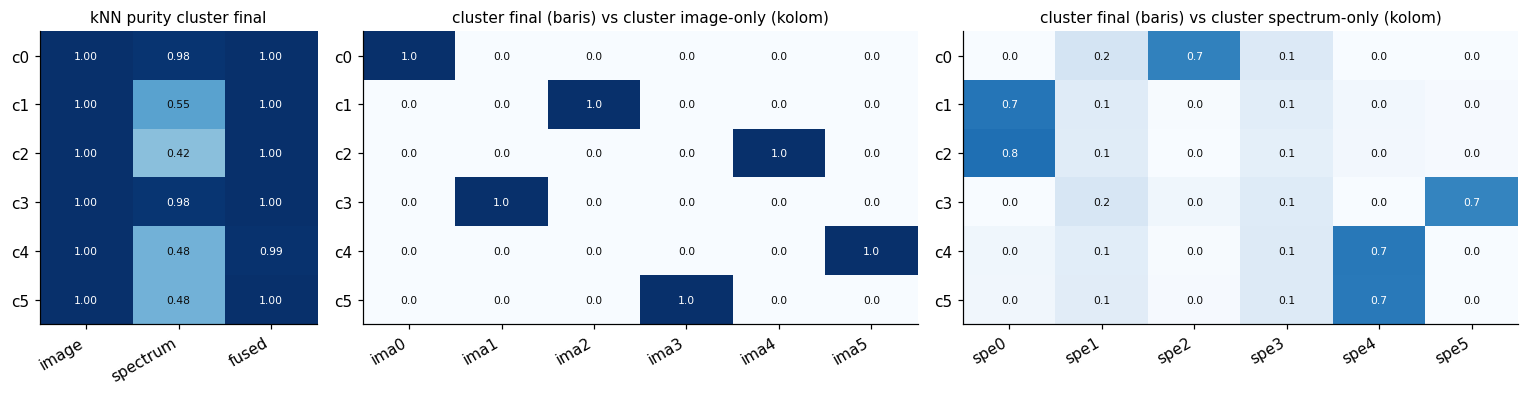

cluster final yang digabung jika hanya memakai image: tidak ada
cluster final yang digabung jika hanya memakai spectrum: [[1, 2], [4, 5]]


In [8]:
final = LABELS[FINAL_METHOD][0]
single = {v: KMeans(K_FINAL, n_init=20, random_state=CFG['seed']).fit_predict(VIEWS[v]) for v in ['image', 'spectrum']}
tab_single = pd.DataFrame({v: {'ARI vs cluster final': adjusted_rand_score(single[v], final),
                               'silhouette cluster final di ruang ini': silhouette_score(VIEWS[v][sil_idx], final[sil_idx])}
                           for v in ['image', 'spectrum']}).T
tab_single.loc['fused'] = [1.0, silhouette_score(X[sil_idx], final[sil_idx])]
display(tab_single.round(4))

pur_idx = np.sort(np.random.default_rng(3).choice(N, min(10000, N), replace=False))
def knn_purity(Xv, lab, idx, k=10):
    nn_ = NearestNeighbors(n_neighbors=min(k + 1, len(idx))).fit(Xv[idx])
    nb = nn_.kneighbors(Xv[idx], return_distance=False)[:, 1:]
    same = (lab[idx][nb] == lab[idx][:, None]).mean(1)
    return pd.Series(same).groupby(lab[idx]).mean()

purity = pd.DataFrame({v: knn_purity(VIEWS[v], final, pur_idx) for v in ['image', 'spectrum', 'fused']})
purity.index.name = 'cluster'
purity['butuh'] = np.select([purity['image'] < purity['fused'] - 0.2, purity['spectrum'] < purity['fused'] - 0.2],
                            ['spectrum', 'image'], 'keduanya cukup')
purity.loc[(purity['image'] < purity['fused'] - 0.2) & (purity['spectrum'] < purity['fused'] - 0.2), 'butuh'] = 'kombinasi'
display(purity.round(3))

def heat(ax, M, rows, cols, title='', vmax=1.0, fmt='.2f'):
    M = np.asarray(M, dtype=float)
    ax.imshow(M, cmap='Blues', vmin=0, vmax=vmax, aspect='auto'); ax.grid(False)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha='right'); ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', fontsize=7,
                        color='white' if M[i, j] > 0.6 * vmax else '#0b0b0b')
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 0.35 * K_FINAL + 1.6), gridspec_kw={'width_ratios': [1, 2, 2]})
heat(axes[0], purity[['image', 'spectrum', 'fused']].values, [f'c{c}' for c in purity.index], ['image', 'spectrum', 'fused'], 'kNN purity cluster final')
for ax, v in zip(axes[1:], ['image', 'spectrum']):
    ct = pd.crosstab(final, single[v]).reindex(index=range(K_FINAL), columns=range(K_FINAL), fill_value=0).values.astype(float)
    heat(ax, ct / np.maximum(ct.sum(1, keepdims=True), 1), [f'c{c}' for c in range(K_FINAL)], [f'{v[:3]}{c}' for c in range(K_FINAL)],
         f'cluster final (baris) vs cluster {v}-only (kolom)', fmt='.1f')
plt.tight_layout(); plt.show()

for v in ['image', 'spectrum']:
    dom = pd.crosstab(final, single[v]).idxmax(1)
    merged_groups = [list(g.index) for _, g in dom.groupby(dom) if len(g) > 1]
    print(f'cluster final yang digabung jika hanya memakai {v}:', merged_groups if merged_groups else 'tidak ada')

**Hasil: apa yang hilang jika hanya satu modalitas.**
- **Image saja** sudah cukup memisahkan keenam cluster: KMeans di ruang image menghasilkan partisi yang hampir sama dengan hasil final (ARI 0.9995), kNN purity semua cluster 0.999–1.000, dan silhouette cluster final di ruang image paling tinggi (0.378). Di data ini, menghilangkan spektrum tidak menghilangkan pemisahan cluster apa pun.
- **Spectrum saja** kehilangan dua pemisahan: cluster 1 tergabung dengan cluster 2, dan cluster 4 tergabung dengan cluster 5 (ARI 0.459 terhadap hasil final). kNN purity spektrum untuk keempat cluster itu hanya 0.42–0.55, sekitar setengah, yang berarti di ruang spektrum tetangga mereka bercampur rata dengan pasangannya. Hanya cluster 0 dan 3 yang tetap terpisah di spektrum (purity 0.98). Kurva rata-rata spektrum di Bagian 8 mengonfirmasi bahwa pasangan c1–c2 dan c4–c5 memiliki spektrum yang praktis identik.

Kesimpulannya, empat dari enam material hanya bisa dibedakan dari mikrostrukturnya, karena komposisinya berpasangan sama. Peran spektrum di hasil final adalah konfirmasi untuk cluster 0 dan 3 serta pembanding yang membuktikan bahwa informasi mikroskop di image embedding adalah efek alat. Spektrum tidak menambah pemisahan baru, dan ini perlu dilaporkan apa adanya.

## 8. Analisis embedding (f)

**Visualisasi 2D.** Embedding diproyeksikan ke 2 dimensi dengan UMAP (atau t-SNE jika UMAP tidak tersedia) pada subsampel. Empat panel:
- Ruang fused diwarnai cluster final.
- Ruang fused diwarnai mikroskop: idealnya M1 dan M2 bercampur rata di setiap cluster.
- Ruang image saja dan ruang spectrum saja diwarnai cluster final: cluster yang menumpuk di salah satu panel adalah cluster yang tidak bisa dipisahkan oleh modalitas tersebut.

Proyeksi 2D hanya alat bantu visual. Jarak antar kelompok di UMAP atau t-SNE tidak bisa ditafsirkan secara langsung, jadi kesimpulan kuantitatif tetap diambil dari tabel.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP selesai dalam 88s


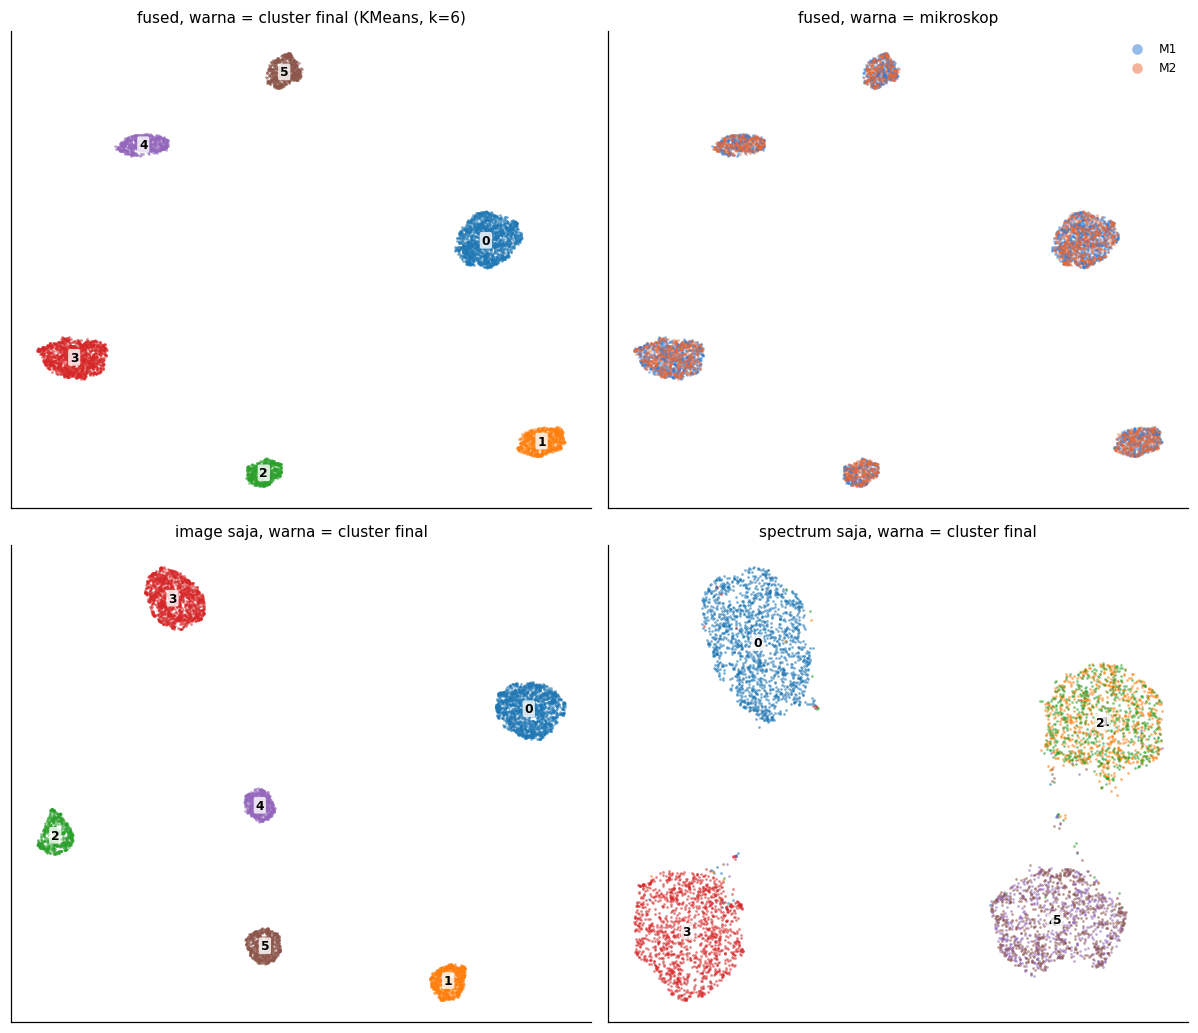

In [9]:
vis_idx = np.sort(np.random.default_rng(4).choice(N, min(CFG['n_vis'], N), replace=False))
def project(Xv):
    if HAS_UMAP:
        return umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=CFG['seed']).fit_transform(Xv)
    return TSNE(2, perplexity=min(30, (len(Xv) - 1) / 3), init='pca', random_state=CFG['seed']).fit_transform(Xv)

t0 = time.time()
P2 = {v: project(VIEWS[v][vis_idx]) for v in ['fused', 'image', 'spectrum']}
print(('UMAP' if HAS_UMAP else 't-SNE'), f'selesai dalam {time.time() - t0:.0f}s')

cmap = plt.get_cmap('tab20' if K_FINAL > 10 else 'tab10')
def scatter_clusters(ax, P, lab, title):
    for c in range(K_FINAL):
        m = lab == c
        if not m.any(): continue
        ax.scatter(P[m, 0], P[m, 1], s=3, color=cmap(c % cmap.N), alpha=0.6, linewidths=0)
        cx, cy = np.median(P[m], 0)
        ax.text(cx, cy, str(c), fontsize=8, fontweight='bold', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
scatter_clusters(axes[0, 0], P2['fused'], final[vis_idx], f'fused, warna = cluster final ({FINAL_METHOD}, k={K_FINAL})')
for m_, name in enumerate(MICS):
    sel = mic[vis_idx] == m_
    axes[0, 1].scatter(P2['fused'][sel, 0], P2['fused'][sel, 1], s=3, color=PAL[m_], alpha=0.5, linewidths=0, label=name)
axes[0, 1].set_title('fused, warna = mikroskop'); axes[0, 1].set_xticks([]); axes[0, 1].set_yticks([]); axes[0, 1].grid(False)
axes[0, 1].legend(markerscale=4)
scatter_clusters(axes[1, 0], P2['image'], final[vis_idx], 'image saja, warna = cluster final')
scatter_clusters(axes[1, 1], P2['spectrum'], final[vis_idx], 'spectrum saja, warna = cluster final')
plt.tight_layout(); plt.show()

**Hasil UMAP.** Di ruang fused terlihat enam pulau yang terpisah jelas tanpa jembatan titik di antaranya. Panel mikroskop menunjukkan M1 dan M2 bercampur rata di setiap pulau, jadi koreksi mikroskop berhasil. Ruang image saja juga membentuk enam pulau yang sama. Ruang spectrum saja hanya membentuk empat kelompok: cluster 0, cluster 3, gabungan cluster 1 dan 2, serta gabungan cluster 4 dan 5. Di dua kelompok gabungan itu warnanya bercampur, sesuai dengan purity spektrum yang rendah.

**Cluster yang sulit dipisahkan.** Untuk setiap pasangan cluster dihitung tingkat percampuran: persentase 10 tetangga terdekat sampel di cluster a yang ternyata berada di cluster b (dirata-rata dua arah). Nilai tinggi berarti batas kedua cluster kabur. Heatmap ditampilkan dalam persen.

**Mengapa nilainya sangat kecil.** Semua percampuran di bawah 0.5%: pasangan tertinggi c4–c5 hanya 0.47%, disusul c0–c1 0.13%. Artinya hampir semua tetangga terdekat setiap sampel berada di cluster yang sama, sesuai dengan kNN purity fused 0.99–1.00. Hal ini tidak bertentangan dengan silhouette yang hanya sekitar 0.25. Silhouette membandingkan jarak rata-rata ke seluruh anggota cluster, dan cluster di data ini cukup lebar, sehingga nilainya sedang. Percampuran kNN hanya melihat tetangga terdekat, dan di antara cluster ada celah kosong, sehingga tetangga hampir tidak pernah menyeberang. Jadi pemisahan antar cluster bersih, meskipun tiap cluster tidak padat.

5 pasangan cluster paling bercampur:


,cluster_a,cluster_b,percampuran
14,4,5,0.0047
0,0,1,0.0013
3,0,4,0.0009
10,2,4,0.0002
7,1,4,0.0002


,ukuran,silhouette,proporsi_M2,purity_image,purity_spectrum
cluster,,,,,
0,10045,0.252,0.400,1.000,0.981
1,4977,0.233,0.402,0.999,0.554
2,3656,0.341,0.407,1.000,0.425
3,8685,0.262,0.391,1.000,0.980
4,4339,0.204,0.399,1.000,0.481
5,4298,0.216,0.400,1.000,0.484


proporsi M2 keseluruhan: 0.399


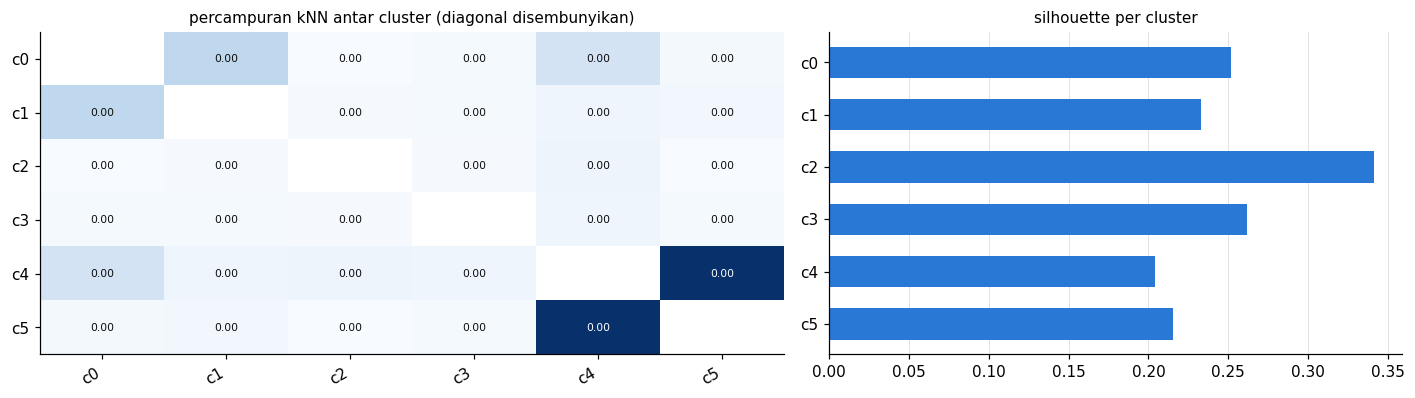

In [10]:
nn_ = NearestNeighbors(n_neighbors=11).fit(X[pur_idx])
nb = nn_.kneighbors(X[pur_idx], return_distance=False)[:, 1:]
lab_p = final[pur_idx]
Mix = np.zeros((K_FINAL, K_FINAL))
for c in range(K_FINAL):
    if (lab_p == c).any():
        Mix[c] = np.bincount(lab_p[nb[lab_p == c]].ravel(), minlength=K_FINAL) / nb[lab_p == c].size
Mix_sym = (Mix + Mix.T) / 2
pairs = pd.DataFrame([(a, b, Mix_sym[a, b]) for a in range(K_FINAL) for b in range(a + 1, K_FINAL)],
                     columns=['cluster_a', 'cluster_b', 'percampuran']).sort_values('percampuran', ascending=False)

sil_s = silhouette_samples(X[sil_idx], final[sil_idx])
per_c = pd.DataFrame({'ukuran': np.bincount(final, minlength=K_FINAL),
                      'silhouette': pd.Series(sil_s).groupby(final[sil_idx]).mean().reindex(range(K_FINAL)),
                      'proporsi_M2': pd.Series(mic).groupby(final).mean().reindex(range(K_FINAL)),
                      'purity_image': purity['image'].reindex(range(K_FINAL)),
                      'purity_spectrum': purity['spectrum'].reindex(range(K_FINAL))})
per_c.index.name = 'cluster'
print('5 pasangan cluster paling bercampur:'); display(pairs.head(5).round(4))
display(per_c.round(3))
print(f'proporsi M2 keseluruhan: {mic.mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * K_FINAL + 1.8), gridspec_kw={'width_ratios': [1.3, 1]})
Mshow = Mix_sym.copy(); np.fill_diagonal(Mshow, np.nan)
heat(axes[0], Mshow, [f'c{c}' for c in range(K_FINAL)], [f'c{c}' for c in range(K_FINAL)],
     'percampuran kNN antar cluster (diagonal disembunyikan)', vmax=max(np.nanmax(Mshow), 1e-6), fmt='.2f')
axes[1].barh(range(K_FINAL), per_c['silhouette'], color=PAL[0], height=0.6)
axes[1].set_yticks(range(K_FINAL)); axes[1].set_yticklabels([f'c{c}' for c in range(K_FINAL)]); axes[1].invert_yaxis()
axes[1].set_title('silhouette per cluster'); axes[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Melihat isi cluster.** Galeri menampilkan 8 citra acak per cluster, diikuti rata-rata spektrum mentah per cluster (garis abu-abu adalah rata-rata seluruh sampel). Bagian terakhir membandingkan langsung pasangan cluster yang paling bercampur, untuk menjelaskan mengapa keduanya sulit dipisahkan: apakah teksturnya mirip, spektrumnya mirip, atau keduanya.

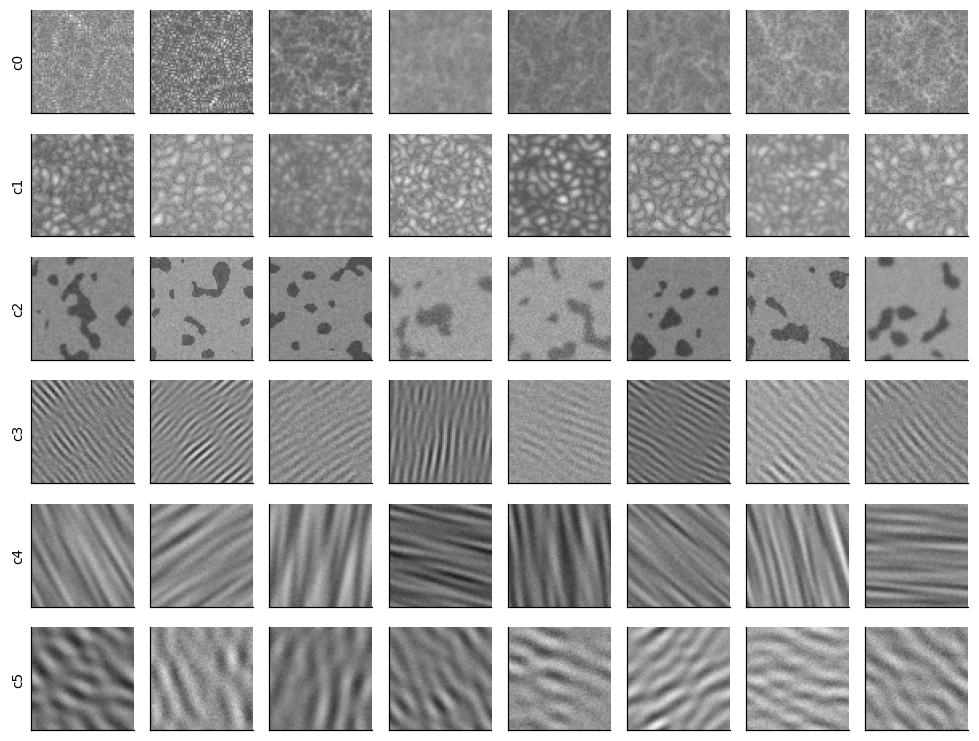

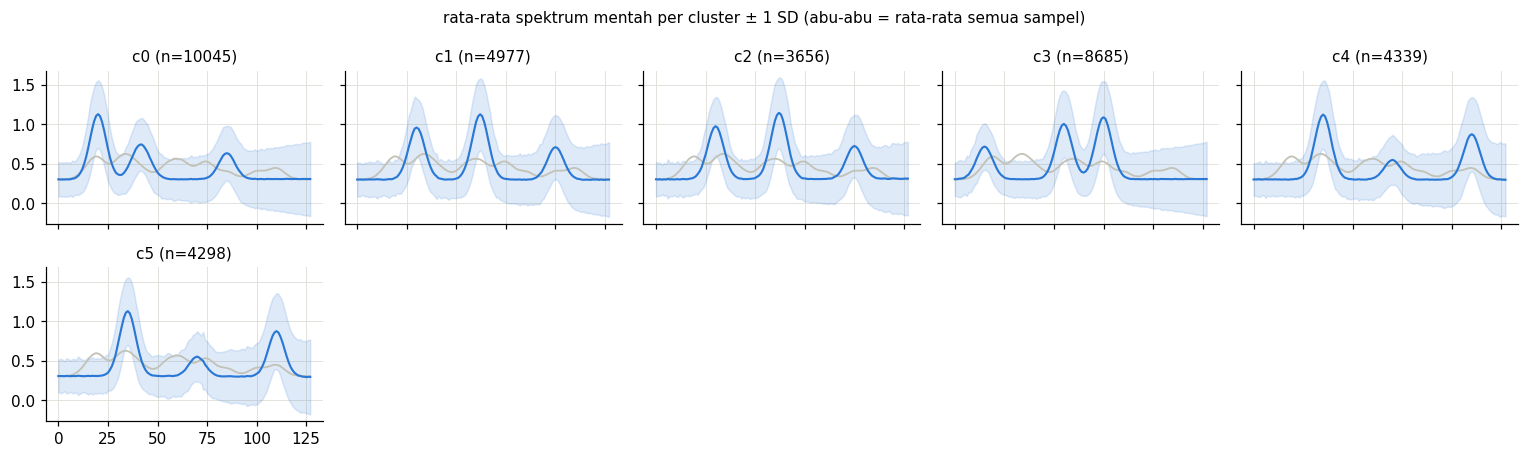

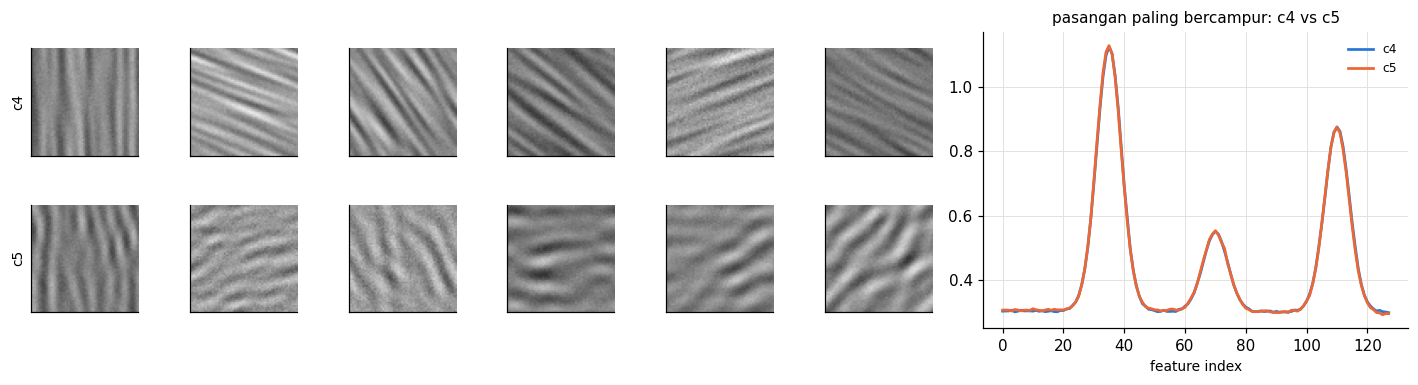

In [11]:
rg = np.random.default_rng(5)
fig, axes = plt.subplots(K_FINAL, 8, figsize=(9, 1.15 * K_FINAL))
axes = np.atleast_2d(axes)
for c in range(K_FINAL):
    pool = np.where(final == c)[0]
    pick = rg.choice(pool, min(8, len(pool)), replace=False) if len(pool) else []
    for j in range(8):
        ax = axes[c, j]; ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j < len(pick): ax.imshow(img_all[pick[j]], cmap='gray', vmin=0, vmax=255)
    axes[c, 0].set_ylabel(f'c{c}', fontsize=9)
plt.tight_layout(); plt.show()

ncol = 5; nrow = math.ceil(K_FINAL / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.1 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel(); g_mean = spec_raw.mean(0)
for c in range(len(axes)):
    ax = axes[c]
    if c >= K_FINAL: ax.axis('off'); continue
    s = spec_raw[final == c]
    ax.plot(g_mean, color='#c3c2b7', lw=1.2)
    if len(s):
        ax.plot(s.mean(0), color=PAL[0], lw=1.4); ax.fill_between(np.arange(128), s.mean(0) - s.std(0), s.mean(0) + s.std(0), color=PAL[0], alpha=0.15)
    ax.set_title(f'c{c} (n={len(s)})')
fig.suptitle('rata-rata spektrum mentah per cluster ± 1 SD (abu-abu = rata-rata semua sampel)', fontsize=10)
plt.tight_layout(); plt.show()

a, b = int(pairs.iloc[0]['cluster_a']), int(pairs.iloc[0]['cluster_b'])
fig = plt.figure(figsize=(13, 3.6)); gs = fig.add_gridspec(2, 9)
for r, c in enumerate([a, b]):
    pool = np.where(final == c)[0]
    for j, i in enumerate(rg.choice(pool, min(6, len(pool)), replace=False)):
        ax = fig.add_subplot(gs[r, j]); ax.imshow(img_all[i], cmap='gray', vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j == 0: ax.set_ylabel(f'c{c}')
ax = fig.add_subplot(gs[:, 6:])
for col, c in zip(PAL[:2], [a, b]):
    ax.plot(spec_raw[final == c].mean(0), color=col, label=f'c{c}')
ax.set_title(f'pasangan paling bercampur: c{a} vs c{b}'); ax.set_xlabel('feature index'); ax.legend()
plt.tight_layout(); plt.show()

**Hasil isi cluster.** Setiap cluster punya mikrostruktur yang konsisten:
- **c0:** jaringan butir halus (batas butir tipis).
- **c1:** struktur sel atau busa dengan dinding gelap.
- **c2:** bintik gelap tidak beraturan di atas matriks terang (dua fase).
- **c3:** lamela diagonal yang sangat halus dan rapat.
- **c4:** lamela lurus yang lebih kasar.
- **c5:** lamela bergelombang.

Rata-rata spektrum memperlihatkan tiga puncak per cluster. Pasangan c1–c2 memiliki puncak di posisi yang sama, begitu juga c4–c5 (sekitar 35, 70, dan 110). Pasangan c4–c5 pada panel terakhir: kedua kurva spektrum bertumpuk sempurna, sedangkan citranya sama-sama berlamela dan hanya berbeda pada bentuk lamela (lurus atau bergelombang). Pita simpangan baku spektrum yang lebar di semua cluster berasal dari variasi baseline dan spike.

**Penjelasan cluster yang sulit dipisahkan.**
1. **c4 vs c5** adalah pasangan tersulit: percampuran kNN tertinggi (0.47%) dan silhouette per cluster terendah (0.204 dan 0.216). Spektrum keduanya identik, sehingga spectrum embedding tidak membantu (purity spektrum 0.48). Satu-satunya pembeda adalah bentuk lamela di citra, yaitu lurus atau bergelombang. Augmentasi rotasi bebas membuat orientasi lamela tidak berpengaruh, sehingga encoder harus membedakan keduanya hanya dari kelengkungan, yang merupakan detail lebih halus daripada perbedaan antar cluster lainnya.
2. **c1 vs c2** juga berbagi spektrum, tetapi mikrostrukturnya sangat berbeda (sel vs bintik dua fase), sehingga mudah dipisahkan lewat citra (c2 punya silhouette tertinggi, 0.341).
3. **c0 vs c1** (0.13%) sama-sama bertekstur jaringan atau sel yang halus. Pada citra yang lebih blur atau berskala kecil, batas butir c0 dan dinding sel c1 bisa terlihat mirip.

Tidak ada cluster yang terbentuk karena mikroskop: proporsi M2 di setiap cluster 0.391–0.407, sangat dekat dengan proporsi keseluruhan 0.399.

## 9. Output cluster.csv & reproduksi

Label dari FINAL_METHOD disimpan ke cluster.csv dengan kolom id_sampel dan cluster (integer), satu baris per sampel sesuai urutan metadata. Nomor cluster bebas karena ARI tidak bergantung pada penamaan. Ringkasan semua pilihan dan metrik disimpan ke ringkasan_clustering.json dan pemilihan_k.csv.

Baris terakhir menjalankan ulang metode final dengan seed pertama (DEC memuat bobot yang tersimpan) lalu membandingkannya dengan cluster.csv. ARI = 1 berarti hasil dapat direproduksi, dan cell ini bisa dipakai saat sesi reproduksi pada ujian lisan.

In [12]:
sub = pd.DataFrame({'id_sampel': meta['id_sampel'].astype(str).values, 'cluster': final.astype(int)})
assert len(sub) == N and sub['id_sampel'].is_unique and sub['cluster'].between(0, K_FINAL - 1).all()
sub.to_csv(OUT_DIR / 'cluster.csv', index=False)
sub.to_csv('cluster.csv', index=False)
print('tersimpan', OUT_DIR / 'cluster.csv', '|', len(sub), 'baris |', sub['cluster'].nunique(), 'cluster')
display(sub.head())
display(sub['cluster'].value_counts().sort_index().rename('jumlah').to_frame().T)

summary = dict(K_FINAL=K_FINAL, k_terbaik_per_kriteria={k: int(v) for k, v in best.items()}, FINAL_METHOD=FINAL_METHOD,
               metode=tab_m.round(4).reset_index().rename(columns={'index': 'metode'}).to_dict(orient='records'),
               single_modality=tab_single.round(4).reset_index().rename(columns={'index': 'ruang'}).to_dict(orient='records'),
               koreksi_mikroskop=tab_leak.round(4).reset_index().rename(columns={'index': 'modalitas'}).to_dict(orient='records'),
               fusion=dict(fuse_dim=CFG['fuse_dim'], w_img=CFG['w_img'], w_spec=CFG['w_spec'],
                           image_file=str(img_path), spectrum_file=str(spec_path)),
               seeds=CFG['seeds'], seed=CFG['seed'])
with open(OUT_DIR / 'ringkasan_clustering.json', 'w') as f:
    json.dump(summary, f, indent=2, default=float)
tab_k.to_csv(OUT_DIR / 'pemilihan_k.csv')

again = METHODS[FINAL_METHOD](X, K_FINAL, CFG['seeds'][0])
saved = pd.read_csv(OUT_DIR / 'cluster.csv')['cluster'].values
print(f'reproduksi {FINAL_METHOD} (k={K_FINAL}) | ARI terhadap cluster.csv = {adjusted_rand_score(saved, again):.4f}')

tersimpan /content/drive/MyDrive/UTS_DL/hasil_tugas3/cluster.csv | 36000 baris | 6 cluster


,id_sampel,cluster
0,S966119,4
1,S315633,3
2,S805122,0
3,S467543,3
4,S475842,3


cluster,0,1,2,3,4,5
jumlah,10045,4977,3656,8685,4339,4298


reproduksi KMeans (k=6) | ARI terhadap cluster.csv = 1.0000
